<a href="https://colab.research.google.com/github/Venus686/Mineria-de-datos/blob/main/Pr%C3%A1ctica2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Pipeline, MinMaxScaler, StandardScaler OneHotEncoder
KBinsDiscretize, SimpleImputer, ColumnTransformer, BaseEstimator, TransformerMixin
RandomOverSampler, RandomUnderSampler

#**PRÁCTICA 2**
##**1. Preparación y partición**
### Ejercicio 1
> Corrige el tipo de TotalCharges (conversión a numérico) y trata los valores ausentes generados.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

dataset = pd.read_csv('/content/Telco-Customer-Churn.csv', na_values=" ")
#Los valores missing están representados con un hueco en blanco.

Con na_values trata los espacios en blanco como NaN, por lo que guarda la variable como float.
Como los valores de TotalCharges corresponden a las personas que llevan 0 meses en la empresa, lo normal es que los cargos totales que le correspondan sea 0, así que como tratamiento voy a llenar estas filas con 0.

In [ ]:
class ConvertirNumerico(BaseEstimator, TransformerMixin):
    def __init__(self, columna):
        self.columna = columna

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        X[self.columna] = pd.to_numeric(
            X[self.columna], errors="coerce").fillna(0)
        return X

pipeline1 = Pipeline([
    ("convertir", ConvertirNumerico("TotalCharges"))
])

dataset_ej1 = pipeline1.fit_transform(dataset)

print(dataset_ej1["TotalCharges"].dtype)
print(dataset_ej1["TotalCharges"].isna().sum())

float64
0


###2. Justifica qué variable eliminarías por ser un identificador sin valor predictivo.

La variable que tenemos como identificador único es customerID, es una variable única que tiene tantas filas distintas como clientes. Por ello mismo, no aporta ningún valor predictivo sobre el abandono de los clientes.

##**2. Transformaciones**

###4. Estudia las variables numéricas (tenure, MonthlyCharges, TotalCharges)¿Cuáles requieren escalado y por qué? Compara StandardScaler (media 0, desviación 1) y MinMaxScaler ([0,1]) e indica cuándo usar cada uno.

In [ ]:
num= ["tenure", "MonthlyCharges", "TotalCharges"]
print(dataset_ej1[num].describe().round(1))

       tenure  MonthlyCharges  TotalCharges
count  7043.0          7043.0        7043.0
mean     32.4            64.8        2279.7
std      24.6            30.1        2266.8
min       0.0            18.2           0.0
25%       9.0            35.5         398.6
50%      29.0            70.4        1394.6
75%      55.0            89.8        3786.6
max      72.0           118.8        8684.8


Las 3 variables pueden beneficiarse del escalado, si observamos los valores min y max de cada atributo, vemos que totalCharges tiene una desviación mucho mayor, por lo que su escala es mayor. Podemos escalar en este caso las 3 variables.

In [ ]:
pipeline4_standard = Pipeline([
    ("scaler", StandardScaler())
])

pipeline4_minmax = Pipeline([
    ("scaler", MinMaxScaler())
])

dataset_standard = dataset_ej1.copy()
dataset_standard[num] = pipeline4_standard.fit_transform(dataset_ej1[num])
dataset_minmax = dataset_ej1.copy()
dataset_minmax[num] = pipeline4_minmax.fit_transform(dataset_ej1[num])

print("\nStandarScaler:")
print(dataset_standard[num].describe().round(2))
print("\nMinMax:")
print(dataset_minmax[num].describe().round(2))


StandarScaler:
        tenure  MonthlyCharges  TotalCharges
count  7043.00         7043.00       7043.00
mean     -0.00           -0.00         -0.00
std       1.00            1.00          1.00
min      -1.32           -1.55         -1.01
25%      -0.95           -0.97         -0.83
50%      -0.14            0.19         -0.39
75%       0.92            0.83          0.66
max       1.61            1.79          2.83

MinMax:
        tenure  MonthlyCharges  TotalCharges
count  7043.00         7043.00       7043.00
mean      0.45            0.46          0.26
std       0.34            0.30          0.26
min       0.00            0.00          0.00
25%       0.12            0.17          0.05
50%       0.40            0.52          0.16
75%       0.76            0.71          0.44
max       1.00            1.00          1.00


MinMaxScaler debe usarse cuando quieres los valores en un rango concreto, y los outlier no son importantes y grandes o han sido tratados anteriormente, y quieres conservar la forma de distribución que había.

StandardScaler debe usarse cuando quieres que las variables tengan una media de 0 y una desviación estándar de 1. Es útil cuando las variables tienen escalas diferentes y quieres que sean comparables. Es sensible a los outliers, por lo que, si existen valores atípicos importantes, conviene analizarlos antes de aplicarlo. No limita los valores a un rango concreto y conserva la forma general de la distribución, aunque la centra y cambia su escala.

###5. Aplica codificación one-hot a las categóricas. ¿Cuántas columnas nuevas se generan?


In [ ]:
categoricas = ['gender','SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
pipeline5 = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

salida5 = pipeline5.fit_transform(dataset_ej1[categoricas])
dataset_one_hot = pd.DataFrame(salida5, columns=pipeline5.get_feature_names_out(),
                               index=dataset_ej1.index)
print(dataset_one_hot.shape)
print("Aumento:", dataset_one_hot.shape[1] - len(categoricas))


(7043, 43)
Aumento: 27


Podemos ver que el dataset tiene 21 columnas, y 16 son categóricas, que son las que se han codificado con el one-hot, el dataset pasa a tener 48 columnas, menos las 5 que no se han modificado (customerID, tenure, MonthlyCharges, TotalCharges y Churn). Por tanto, se generan 43 columnas nuevas, que sustituyen a las 16 originales, lo que supone un aumento de 27 columnas.

###6. Construye el ColumnTransformer que integre todas las transformaciones.

In [ ]:

numericas = ["tenure", "MonthlyCharges", "TotalCharges"]
categoricas = ['gender','SeniorCitizen','Partner','Dependents','PhoneService',
               'MultipleLines','InternetService','OnlineSecurity','OnlineBackup',
               'DeviceProtection','TechSupport','StreamingTV','StreamingMovies',
               'Contract','PaperlessBilling','PaymentMethod']

numericas_pipeline = Pipeline([
    ('scaler', StandardScaler())
])

categoricas_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder())
])

dividir_num_cat= ColumnTransformer(
    [
        ('etapa_num', numericas_pipeline, numericas),
        ('etapa_categorica', categoricas_pipeline, categoricas)
    ]
)
pipeline6 = Pipeline([
    ('dividir_num_cat', dividir_num_cat)
])

salida = pipeline6.fit_transform(dataset_ej1)
salida_df = pd.DataFrame(salida, columns=pipeline6.get_feature_names_out(), index=dataset_ej1.index)
salida_df.head()

,etapa_num__tenure,etapa_num__MonthlyCharges,etapa_num__TotalCharges,etapa_categorica__gender_Female,etapa_categorica__gender_Male,etapa_categorica__SeniorCitizen_0,etapa_categorica__SeniorCitizen_1,etapa_categorica__Partner_No,etapa_categorica__Partner_Yes,etapa_categorica__Dependents_No,...,etapa_categorica__StreamingMovies_Yes,etapa_categorica__Contract_Month-to-month,etapa_categorica__Contract_One year,etapa_categorica__Contract_Two year,etapa_categorica__PaperlessBilling_No,etapa_categorica__PaperlessBilling_Yes,etapa_categorica__PaymentMethod_Bank transfer (automatic),etapa_categorica__PaymentMethod_Credit card (automatic),etapa_categorica__PaymentMethod_Electronic check,etapa_categorica__PaymentMethod_Mailed check
0,-1.277445,-1.160323,-0.992611,1.0,0.0,1.0,0.0,0.0,1.0,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,0.066327,-0.259629,-0.172165,0.0,1.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,-1.236724,-0.362660,-0.958066,0.0,1.0,1.0,0.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,0.514251,-0.746535,-0.193672,0.0,1.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,-1.236724,0.197365,-0.938874,1.0,0.0,1.0,0.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


##**3. Feature engineering**

###7. Crea una variable num_services que cuente los servicios contratados ("Yes" en las columnas de servicios). Relaciónala con Churn.


num_services
0    43.750000
1    21.105232
2    32.828283
3    36.476684
4    31.344902
5    25.550661
6    22.485207
7    12.405063
8     5.288462
Name: Churn, dtype: float64


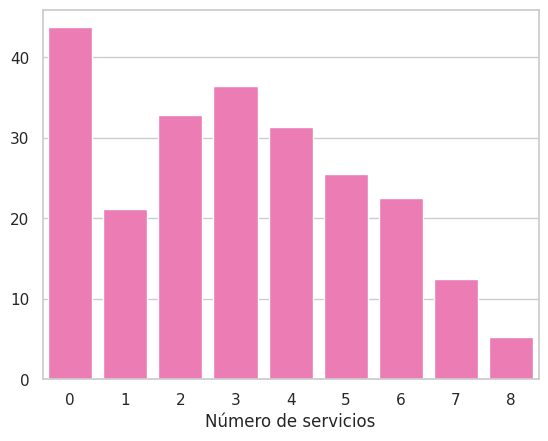

In [ ]:
servicios = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
             "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

class NumServicios(TransformerMixin, BaseEstimator):
    def __init__(self, servicios=None):
        self.servicios = servicios
    def fit(self, X, y=None):
        self.is_fitted_ = True
        return self
    def transform(self, X):
        X = X.copy()
        X["num_services"] = (X[self.servicios] == "Yes").sum(axis=1)
        return X

pipeline_servicios = Pipeline([
    ("num_servicios", NumServicios(servicios=servicios))
])

dataset_servicios = pipeline_servicios.fit_transform(dataset)
relacion_churn = dataset_servicios.groupby("num_services")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)

print(relacion_churn)
sns.barplot(x=relacion_churn.index, y=relacion_churn.values, color="hotpink")
plt.xlabel("Número de servicios")
plt.show()

Como podemos observar, los clientes que más abandonas son los que menos servicios tienen.

---
###8. Crea avg_monthly_charge = TotalCharges / max(tenure, 1). ¿Aporta información más allá de MonthlyCharges? Justifícalo con un gráfico.


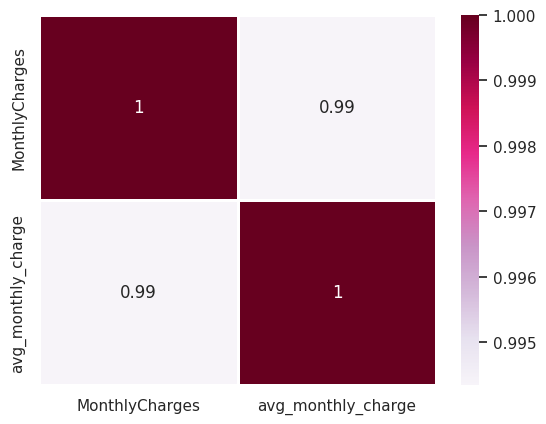

----


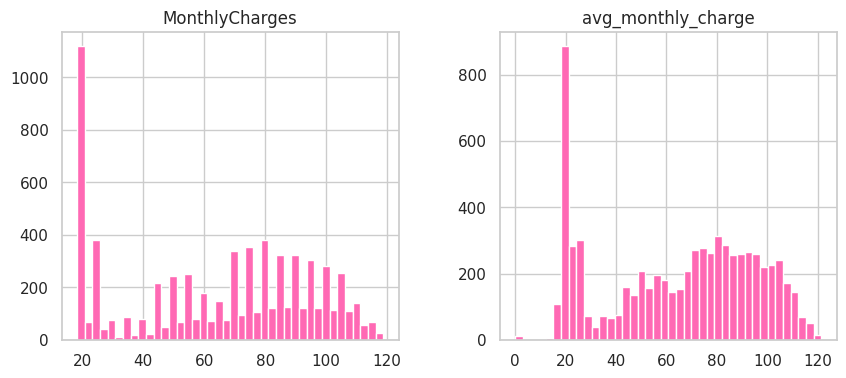

In [ ]:

class MyTransformer(TransformerMixin, BaseEstimator):
    def __init__(self, *, param=1):
        None
    def fit(self, dataset, y=None):
        return self
    def transform(self, dataset):
        X = dataset.copy()
        tenure = np.maximum(X["tenure"], 1)
        X["avg_monthly_charge"] = X["TotalCharges"] / tenure
        return X

pipeline8= MyTransformer()
datos = pipeline8.fit_transform(dataset_ej1)
columnas = ["MonthlyCharges", "avg_monthly_charge"]

corr = datos[columnas].corr()
sns.heatmap(corr, annot=True, cmap="PuRd", linewidths=2, linecolor="white")
plt.show()
print("----")

datos[columnas].hist(bins=40, color="hotpink", edgecolor="white", figsize=(10, 4))
plt.show()

La información que aporta es redundante, porque ambas tienen una  correlación del 99%.

---
### 9. Documenta cada variable creada y por qué debería ayudar al modelo

### `num_services`
- Es el número de servicios contratados por el cliente (0 a 8). Cuenta las columnas con valor "Yes".
Resume en un solo número el grado de
  vinculación del cliente con la empresa. Los clientes que abandonan tienen de media
  menos servicios, esta información puede ser util, para evitar el abandono de los clientes.
### `avg_monthly_charge`
- MonthlyCharges es la cuota actual, mientras que esta variable refleja lo que el cliente ha pagado de media históricamente. Pero como tienen una correlación de 0.994 es casi redundante añadirla.

---
##**4. Reproducibilidad**

###10. Encapsula todo el preprocesamiento en un objeto Pipeline/ColumnTransformer.

In [ ]:
numericas_final = num + ["num_services", "avg_monthly_charge"]

dividir_final = ColumnTransformer([
    ('etapa_num', pipeline4_standard, numericas_final),
    ('etapa_categorica', pipeline5, categoricas)
])

pipeline10 = Pipeline([
    ('ej1', pipeline1),
    ('ej7', pipeline_servicios),
    ('ej8', pipeline8),
    ('ej6', dividir_final)
])

salida10 = pipeline10.fit_transform(dataset)

columnas10 = pipeline10.named_steps['ej6'].get_feature_names_out()
salida10_df = pd.DataFrame(salida10, columns=columnas10, index=dataset.index)

salida10_df.head()

,etapa_num__tenure,etapa_num__MonthlyCharges,etapa_num__TotalCharges,etapa_num__num_services,etapa_num__avg_monthly_charge,etapa_categorica__gender_Female,etapa_categorica__gender_Male,etapa_categorica__SeniorCitizen_0,etapa_categorica__SeniorCitizen_1,etapa_categorica__Partner_No,...,etapa_categorica__StreamingMovies_Yes,etapa_categorica__Contract_Month-to-month,etapa_categorica__Contract_One year,etapa_categorica__Contract_Two year,etapa_categorica__PaperlessBilling_No,etapa_categorica__PaperlessBilling_Yes,etapa_categorica__PaymentMethod_Bank transfer (automatic),etapa_categorica__PaymentMethod_Credit card (automatic),etapa_categorica__PaymentMethod_Electronic check,etapa_categorica__PaymentMethod_Mailed check
0,-1.277445,-1.160323,-0.992611,-1.145997,-1.151302,1.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,0.066327,-0.259629,-0.172165,-0.176011,-0.301458,0.0,1.0,1.0,0.0,1.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,-1.236724,-0.362660,-0.958066,-0.176011,-0.350966,0.0,1.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,0.514251,-0.746535,-0.193672,-0.176011,-0.786053,0.0,1.0,1.0,0.0,1.0,...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,-1.236724,0.197365,-0.938874,-1.145997,0.367602,1.0,0.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


---


# Parte optativa
### • Implementa un transformador propio heredando de BaseEstimator y TransformerMixin (por ejemplo, un discretizador de tenure o un contador de servicios)